# 1. Setup and Paths

This notebook prepares a manageable subset of the Wellington Camera Traps dataset for wildlife classification and predator early-warning experiments.

The raw dataset is kept unchanged under `data/raw/`. Selected metadata and extracted images will be written to `data/interim/` and `data/processed/`.

In [3]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

CSV_PATH = RAW_DATA_DIR / "wellington_camera_traps.csv"
JSON_PATH = RAW_DATA_DIR / "wellington_camera_traps.json"

# Large archive stored outside the repository
ZIP_PATH = Path(r"D:\download\wct_images.zip")

INTERIM_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("CSV exists:", CSV_PATH.exists())
print("JSON exists:", JSON_PATH.exists())
print("ZIP exists:", ZIP_PATH.exists())

Project root: e:\Code\ai-predator-early-warning
CSV exists: True
JSON exists: True
ZIP exists: True


# 2. Load Metadata

The CSV metadata contains one row per camera-trap image, including the filename, label, site, date, and camera information.

In [4]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (270450, 7)
Columns: ['sequence', 'image_sequence', 'file', 'label', 'site', 'date', 'camera']


,sequence,image_sequence,file,label,site,date,camera
0,2,image1,290716114012001a1116.jpg,BIRD,001a,7/29/2016 11:40,111
1,12,image1,100816090812001a1111.jpg,BIRD,001a,8/10/2016 9:08,111
2,17,image1,180516121622001a1602.jpg,BIRD,001a,5/18/2016 12:16,160
3,18,image1,260416120224001a1601.jpg,BIRD,001a,4/26/2016 12:02,160
4,20,image1,160516023810001a1606.jpg,CAT,001a,5/16/2016 2:38,160


In [5]:
label_counts = df["label"].value_counts()

label_counts

label
BIRD              154525
NOTHINGHERE        45721
CAT                30285
HEDGEHOG           10706
MOUSE               6481
RABBIT              5714
POSSUM              4351
UNCLASSIFIABLE      3484
Ship rat            3183
RAT                 2757
DOG                  998
Norway rat           861
GOAT                 645
DEER                 312
HARE                 207
PIG                  193
MUSTELID              27
Name: count, dtype: int64

In [6]:
site_counts = (
    df.groupby("label")["site"]
    .nunique()
    .sort_values(ascending=False)
)

site_counts

label
BIRD              213
NOTHINGHERE       207
CAT               187
UNCLASSIFIABLE    180
HEDGEHOG          161
MOUSE             129
RAT               110
POSSUM             80
RABBIT             61
Ship rat           53
DOG                46
Norway rat         23
HARE               22
GOAT                7
PIG                 7
MUSTELID            6
DEER                6
Name: site, dtype: int64

In [7]:
label_summary = pd.DataFrame({
    "images": label_counts,
    "sites": site_counts
}).fillna(0).astype(int)

label_summary

,images,sites
label,,
BIRD,154525,213
CAT,30285,187
DEER,312,6
DOG,998,46
GOAT,645,7
HARE,207,22
HEDGEHOG,10706,161
MOUSE,6481,129
MUSTELID,27,6


# 3. Define Project Classes

To keep the classification task manageable, related rodent labels are combined into a single `RODENT` class.

The project uses six classes:

- `BIRD`
- `CAT`
- `HEDGEHOG`
- `POSSUM`
- `RODENT`
- `EMPTY`

`EMPTY` corresponds to the original `NOTHINGHERE` label.

In [12]:
RODENT_LABELS = {
    "MOUSE",
    "RAT",
    "Ship rat",
    "Norway rat"
}

def map_project_class(label):
    if label == "BIRD":
        return "BIRD"
    elif label == "CAT":
        return "CAT"
    elif label == "HEDGEHOG":
        return "HEDGEHOG"
    elif label == "POSSUM":
        return "POSSUM"
    elif label in RODENT_LABELS:
        return "RODENT"
    elif label == "NOTHINGHERE":
        return "EMPTY"
    else:
        return None

df["project_class"] = df["label"].apply(map_project_class)

project_df = df[df["project_class"].notna()].copy()

project_summary = (
    project_df.groupby("project_class")
    .agg(
        images=("file", "count"),
        sites=("site", "nunique")
    )
    .sort_values("images", ascending=False)
)

project_summary

,images,sites
project_class,,
BIRD,154525,213
EMPTY,45721,207
CAT,30285,187
RODENT,13282,157
HEDGEHOG,10706,161
POSSUM,4351,80


# 4. Select Sample Size

To reduce training cost and avoid severe class imbalance, a balanced subset of 3,000 images per class will be used.

This gives a total of 18,000 images across six classes.

In [13]:
N_PER_CLASS = 3000

class_sample_plan = pd.DataFrame({
    "available": project_summary["images"],
    "selected": N_PER_CLASS
})

class_sample_plan

,available,selected
project_class,,
BIRD,154525,3000
EMPTY,45721,3000
CAT,30285,3000
RODENT,13282,3000
HEDGEHOG,10706,3000
POSSUM,4351,3000


# 5. Select Sample Size

To keep the dataset balanced and computationally manageable, a fixed number of images will be selected from each project class.

For the first version of the dataset, 3,000 images will be sampled from each of the six classes, giving a total of 18,000 images.

In [17]:
N_PER_CLASS = 3000
RANDOM_STATE = 42

selected_parts = []

for cls, group in project_df.groupby("project_class"):
    sampled = group.sample(
        n=N_PER_CLASS,
        random_state=RANDOM_STATE
    )
    selected_parts.append(sampled)

selected_df = pd.concat(selected_parts, ignore_index=True)

selected_df["project_class"].value_counts()

project_class
BIRD        3000
CAT         3000
EMPTY       3000
HEDGEHOG    3000
POSSUM      3000
RODENT      3000
Name: count, dtype: int64

In [18]:
selected_df[["file", "label", "project_class", "site"]].head()

,file,label,project_class,site
0,260616095442043a7512.jpg,BIRD,BIRD,043a
1,190516125522009a3423.jpg,BIRD,BIRD,009a
2,090116153634047a1111.jpg,BIRD,BIRD,047a
3,140416163830049c5352.jpg,BIRD,BIRD,049c
4,160816105306023a6243.jpg,BIRD,BIRD,023a


In [19]:
SELECTED_METADATA_PATH = INTERIM_DATA_DIR / "selected_metadata.csv"

selected_df.to_csv(
    SELECTED_METADATA_PATH,
    index=False
)

print("Saved to:", SELECTED_METADATA_PATH)

Saved to: e:\Code\ai-predator-early-warning\data\interim\selected_metadata.csv


# 6. Split by Site

To reduce location and background leakage, the dataset is split by camera-trap site rather than by individual images.

All images from the same site are assigned to only one of the training, validation, or test sets.

The target split is approximately:

- 70% training
- 15% validation
- 15% test

In [20]:
from sklearn.model_selection import GroupShuffleSplit

TARGET_RATIOS = {
    "train": 0.70,
    "val": 0.15,
    "test": 0.15
}

TRAIN_PER_CLASS = 2100
VAL_PER_CLASS = 450
TEST_PER_CLASS = 450

PROJECT_CLASSES = [
    "BIRD",
    "CAT",
    "HEDGEHOG",
    "POSSUM",
    "RODENT",
    "EMPTY"
]

def split_by_site(data, random_state):
    """
    Split the dataset by site:
    70% of sites -> train
    15% of sites -> validation
    15% of sites -> test
    """

    # First split: 70% train sites, 30% temporary sites
    first_split = GroupShuffleSplit(
        n_splits=1,
        train_size=0.70,
        random_state=random_state
    )

    train_idx, temp_idx = next(
        first_split.split(
            data,
            groups=data["site"]
        )
    )

    train_pool = data.iloc[train_idx].copy()
    temp_pool = data.iloc[temp_idx].copy()

    # Second split: divide remaining sites equally
    # 15% validation, 15% test
    second_split = GroupShuffleSplit(
        n_splits=1,
        train_size=0.50,
        random_state=random_state + 1
    )

    val_idx, test_idx = next(
        second_split.split(
            temp_pool,
            groups=temp_pool["site"]
        )
    )

    val_pool = temp_pool.iloc[val_idx].copy()
    test_pool = temp_pool.iloc[test_idx].copy()

    return train_pool, val_pool, test_pool

In [22]:
def has_enough_samples(split_df, required_per_class):
    counts = split_df["project_class"].value_counts()

    for cls in PROJECT_CLASSES:
        if counts.get(cls, 0) < required_per_class:
            return False

    return True

def calculate_split_score(train_pool, val_pool, test_pool):
    total_images = (
        len(train_pool)
        + len(val_pool)
        + len(test_pool)
    )

    actual_ratios = {
        "train": len(train_pool) / total_images,
        "val": len(val_pool) / total_images,
        "test": len(test_pool) / total_images
    }

    score = sum(
        abs(actual_ratios[split] - TARGET_RATIOS[split])
        for split in TARGET_RATIOS
    )

    return score, actual_ratios

In [24]:
best_split = None
best_score = float("inf")
best_seed = None
best_ratios = None

for seed in range(1000):

    train_pool, val_pool, test_pool = split_by_site(
        project_df,
        random_state=seed
    )

    # Check whether every split has enough images
    if not has_enough_samples(
        train_pool,
        TRAIN_PER_CLASS
    ):
        continue

    if not has_enough_samples(
        val_pool,
        VAL_PER_CLASS
    ):
        continue

    if not has_enough_samples(
        test_pool,
        TEST_PER_CLASS
    ):
        continue

    score, ratios = calculate_split_score(
        train_pool,
        val_pool,
        test_pool
    )

    if score < best_score:
        best_score = score
        best_seed = seed
        best_ratios = ratios
        best_split = (
            train_pool,
            val_pool,
            test_pool
        )


if best_split is None:
    raise ValueError(
        "No suitable site-based split was found. "
        "Try reducing the number of selected images per class."
    )

train_pool, val_pool, test_pool = best_split

print("Best random seed:", best_seed)
print("Split score:", round(best_score, 4))

print("\nImage ratios:")
for split, ratio in best_ratios.items():
    print(f"{split}: {ratio:.2%}")


print("\nNumber of sites:")
print("Train:", train_pool["site"].nunique())
print("Validation:", val_pool["site"].nunique())
print("Test:", test_pool["site"].nunique())

train_sites = set(train_pool["site"])
val_sites = set(val_pool["site"])
test_sites = set(test_pool["site"])

print("\nSite overlap:")
print("Train ∩ Val:", len(train_sites & val_sites))
print("Train ∩ Test:", len(train_sites & test_sites))
print("Val ∩ Test:", len(val_sites & test_sites))


split_class_summary = pd.DataFrame({
    "train": train_pool["project_class"].value_counts(),
    "val": val_pool["project_class"].value_counts(),
    "test": test_pool["project_class"].value_counts()
}).fillna(0).astype(int)

split_class_summary

Best random seed: 624
Split score: 0.0016

Image ratios:
train: 70.08%
val: 14.95%
test: 14.97%

Number of sites:
Train: 150
Validation: 32
Test: 33

Site overlap:
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


,train,val,test
project_class,,,
BIRD,109050,22222,23253
EMPTY,33390,6298,6033
CAT,20504,5158,4623
RODENT,8667,2382,2233
HEDGEHOG,6469,2102,2135
POSSUM,3337,536,478


# 7. Sample Final Train / Validation / Test Sets

A fixed number of images is sampled from each class within the site-based training, validation, and test pools.

This creates a balanced dataset with:

- 2,100 images per class for training
- 450 images per class for validation
- 450 images per class for testing

Each class therefore contains 3,000 images in total.

In [28]:
RANDOM_STATE = 42

def sample_per_class(data, n_per_class, random_state):
    sampled_parts = []

    for cls in PROJECT_CLASSES:
        class_data = data[
            data["project_class"] == cls
        ]

        sampled = class_data.sample(
            n=n_per_class,
            random_state=random_state
        )

        sampled_parts.append(sampled)

    return pd.concat(
        sampled_parts,
        ignore_index=True
    )

train_df = sample_per_class(
    train_pool,
    n_per_class=TRAIN_PER_CLASS,
    random_state=RANDOM_STATE
)

val_df = sample_per_class(
    val_pool,
    n_per_class=VAL_PER_CLASS,
    random_state=RANDOM_STATE
)

test_df = sample_per_class(
    test_pool,
    n_per_class=TEST_PER_CLASS,
    random_state=RANDOM_STATE
)

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

selected_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)


final_summary = pd.crosstab(
    selected_df["project_class"],
    selected_df["split"]
)

final_summary

split,test,train,val
project_class,,,
BIRD,450,2100,450
CAT,450,2100,450
EMPTY,450,2100,450
HEDGEHOG,450,2100,450
POSSUM,450,2100,450
RODENT,450,2100,450


In [29]:
train_sites_final = set(
    selected_df.loc[
        selected_df["split"] == "train",
        "site"
    ]
)

val_sites_final = set(
    selected_df.loc[
        selected_df["split"] == "val",
        "site"
    ]
)

test_sites_final = set(
    selected_df.loc[
        selected_df["split"] == "test",
        "site"
    ]
)

print("Train ∩ Val:", len(train_sites_final & val_sites_final))
print("Train ∩ Test:", len(train_sites_final & test_sites_final))
print("Val ∩ Test:", len(val_sites_final & test_sites_final))

Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [30]:
SELECTED_METADATA_PATH = (
    INTERIM_DATA_DIR / "selected_metadata.csv"
)

selected_df.to_csv(
    SELECTED_METADATA_PATH,
    index=False
)

print("Saved to:", SELECTED_METADATA_PATH)

Saved to: e:\Code\ai-predator-early-warning\data\interim\selected_metadata.csv


# 8. Extract Selected Images from ZIP

Only the selected images are extracted from the original image archive.

Images are organised by dataset split and project class so that the processed dataset can be loaded directly for model training.

In [31]:
import zipfile
import shutil

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    zip_names = zip_file.namelist()

print("Files in ZIP:", len(zip_names))

for name in zip_names[:10]:
    print(name)

Files in ZIP: 270451
images/
images/010116002950005as381.JPG
images/010116002950005as382.JPG
images/010116002952005as383.JPG
images/010116004822024b7481.JPG
images/010116004822024b7482.JPG
images/010116004824024b7483.JPG
images/010116005220041as531.JPG
images/010116005222041as532.JPG
images/010116005222041as533.JPG


## 8.1 Check Selected Filenames

The CSV stores image filenames only, while the ZIP archive stores them under the `images/` folder.

Before extraction, the selected filenames are checked against the archive to ensure that all required images are available.

In [32]:
selected_df["zip_path"] = (
    "images/" + selected_df["file"].astype(str)
)

selected_df[
    ["file", "zip_path", "project_class", "split"]
].head()

,file,zip_path,project_class,split
0,130616115348005as131.jpg,images/130616115348005as131.jpg,BIRD,train
1,1106150852100835S082.jpg,images/1106150852100835S082.jpg,BIRD,train
2,210916072714043as433.jpg,images/210916072714043as433.jpg,BIRD,train
3,240916111910017as082.jpg,images/240916111910017as082.jpg,BIRD,train
4,161016171542019b9705.jpg,images/161016171542019b9705.jpg,BIRD,train


In [ ]:
#Then check whether all these paths exist

zip_name_set = set(zip_names)

selected_df["found_in_zip"] = (
    selected_df["zip_path"].isin(zip_name_set)
)

selected_df["found_in_zip"].value_counts()

found_in_zip
False    18000
Name: count, dtype: int64

## 8.2 Extract Selected Images

The selected images are extracted into `train`, `val`, and `test` folders, with one subfolder per project class.

In [36]:
for split in ["train", "val", "test"]:
    for cls in PROJECT_CLASSES:
        output_folder = PROCESSED_DATA_DIR / split / cls
        output_folder.mkdir(parents=True, exist_ok=True)

# Build a case-insensitive lookup:
# lowercase path -> real path inside ZIP
zip_lookup = {
    name.lower(): name
    for name in zip_names
}

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    total = len(selected_df)

    for i, row in selected_df.iterrows():

        requested_path = (
            "images/" + str(row["file"])
        )

        # Find the real ZIP path regardless of upper/lower case
        actual_zip_path = zip_lookup.get(
            requested_path.lower()
        )

        if actual_zip_path is None:
            print("Missing:", requested_path)
            continue

        target_path = (
            PROCESSED_DATA_DIR
            / row["split"]
            / row["project_class"]
            / Path(row["file"]).name
        )

        # Skip images that were already extracted
        if target_path.exists():
            continue

        with zip_file.open(actual_zip_path) as src, \
             open(target_path, "wb") as dst:

            shutil.copyfileobj(src, dst)

        if (i + 1) % 500 == 0:
            print(f"Processed {i + 1}/{total}")

print("Extraction complete.")
        

Processed 500/18000
Processed 1000/18000
Processed 1500/18000
Processed 2000/18000
Processed 2500/18000
Processed 3000/18000
Processed 3500/18000
Processed 4000/18000
Processed 4500/18000
Processed 5000/18000
Processed 5500/18000
Processed 6000/18000
Processed 6500/18000
Processed 7000/18000
Processed 7500/18000
Processed 8000/18000
Processed 8500/18000
Processed 9000/18000
Processed 9500/18000
Processed 10000/18000
Processed 10500/18000
Processed 11000/18000
Processed 11500/18000
Processed 12000/18000
Processed 12500/18000
Processed 13000/18000
Processed 13500/18000
Processed 14000/18000
Processed 14500/18000
Processed 15000/18000
Processed 15500/18000
Processed 16000/18000
Processed 16500/18000
Processed 17000/18000
Processed 17500/18000
Processed 18000/18000
Extraction complete.


# 9. Data Quality Screening
## 9.1 Calculate Image Quality Metrics

In [52]:
from PIL import Image
import numpy as np

def calculate_image_quality(image_path):
    image = Image.open(image_path).convert("L")
    image = image.resize((256, 192))

    pixels = np.array(image)

    overexposed_ratio = np.mean(pixels >= 245)
    brightness = pixels.mean()
    contrast = pixels.std()

    return overexposed_ratio, brightness, contrast

## 9.2 Run Quality Screening on All Selected Images

In [53]:
quality_records = []

for _, row in selected_df.iterrows():
    image_path = (
        PROCESSED_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    try:
        overexposure, brightness, contrast = calculate_image_quality(image_path)

        quality_records.append({
            "file": row["file"],
            "project_class": row["project_class"],
            "split": row["split"],
            "overexposed_ratio": overexposure,
            "brightness": brightness,
            "contrast": contrast
        })

    except Exception:
        quality_records.append({
            "file": row["file"],
            "project_class": row["project_class"],
            "split": row["split"],
            "overexposed_ratio": None,
            "brightness": None,
            "contrast": None
        })

quality_df = pd.DataFrame(quality_records)

## 9.3 Assign Quality Status

In [54]:
quality_df["hard_reject"] = (
    (quality_df["overexposed_ratio"] > 0.60)
    |
    (
        (quality_df["brightness"] > 240)
        & (quality_df["contrast"] < 25)
    )
    |
    (quality_df["brightness"] < 20)
)

quality_df["needs_review"] = (
    ~quality_df["hard_reject"]
    &
    (
        (quality_df["overexposed_ratio"] > 0.40)
        | (quality_df["brightness"] < 30)
        | (quality_df["contrast"] < 25)
    )
)

def get_quality_status(row):
    if row["hard_reject"]:
        return "reject"
    elif row["needs_review"]:
        return "review"
    else:
        return "keep"

quality_df["quality_status"] = quality_df.apply(
    get_quality_status,
    axis=1
)

In [55]:
# Check Quality Distribution
quality_df["quality_status"].value_counts()

quality_status
keep      16852
review      931
reject      217
Name: count, dtype: int64

In [ ]:
#  Save Quality Metadata
QUALITY_METADATA_PATH = (
    INTERIM_DATA_DIR / "image_quality.csv"
)

quality_df.to_csv(
    QUALITY_METADATA_PATH,
    index=False
)

print("Saved to:", QUALITY_METADATA_PATH)

Saved to: e:\Code\ai-predator-early-warning\data\interim\image_quality.csv


In [57]:
#  Check Quality by Class

quality_by_class = pd.crosstab(
    quality_df["project_class"],
    quality_df["quality_status"]
)

quality_by_class

quality_status,keep,reject,review
project_class,,,
BIRD,2708,25,267
CAT,2818,27,155
EMPTY,2741,39,220
HEDGEHOG,2792,60,148
POSSUM,2956,1,43
RODENT,2837,65,98


## 9.4 Create Strict Train/Val and Realistic Test

For training and validation, remove both `reject` and `review` images.

For testing, remove only `reject` images.

This keeps training cleaner, while still keeping a more realistic test set.

In [58]:
strict_clean_df = selected_df.merge(
    quality_df[["file", "quality_status"]],
    on="file",
    how="left"
)

train_clean_df = strict_clean_df[
    (strict_clean_df["split"] == "train")
    & (strict_clean_df["quality_status"] == "keep")
].copy()

val_clean_df = strict_clean_df[
    (strict_clean_df["split"] == "val")
    & (strict_clean_df["quality_status"] == "keep")
].copy()

test_clean_df = strict_clean_df[
    (strict_clean_df["split"] == "test")
    & (strict_clean_df["quality_status"] != "reject")
].copy()

final_clean_df = pd.concat(
    [train_clean_df, val_clean_df, test_clean_df],
    ignore_index=True
)

print("Original size:", len(selected_df))
print("Final clean size:", len(final_clean_df))
print("Removed:", len(selected_df) - len(final_clean_df))

Original size: 18000
Final clean size: 16962
Removed: 1038


In [ ]:
# Check Final Dataset Size

final_summary = pd.crosstab(
    final_clean_df["project_class"],
    final_clean_df["split"]
)

#final_summary

split,test,train,val
project_class,,,
BIRD,448,1869,419
CAT,450,1999,402
EMPTY,444,1904,418
HEDGEHOG,450,1953,396
POSSUM,450,2064,450
RODENT,450,2011,385


In [ ]:
# Save Final Metadata
FINAL_METADATA_PATH = (
    INTERIM_DATA_DIR / "final_clean_metadata.csv"
)

final_clean_df.to_csv(
    FINAL_METADATA_PATH,
    index=False
)

print("Saved to:", FINAL_METADATA_PATH)

Saved to: e:\Code\ai-predator-early-warning\data\interim\final_clean_metadata.csv


## 9.5 Move Excluded Images

Images that are not included in the final dataset are moved to a separate folder.

This keeps the training folders clean while preserving excluded images for later analysis.

In [61]:
EXCLUDED_DATA_DIR = PROJECT_ROOT / "data" / "excluded"

EXCLUDED_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

keep_files = set(
    zip(
        final_clean_df["split"],
        final_clean_df["project_class"],
        final_clean_df["file"]
    )
)

print("Images to keep:", len(keep_files))

Images to keep: 16962


In [64]:
# Move Images Not Used for Training

import shutil

moved_count = 0

for _, row in selected_df.iterrows():
    key = (
        row["split"],
        row["project_class"],
        row["file"]
    )

    # Keep images in the final dataset
    if key in keep_files:
        continue

    source_path = (
        PROCESSED_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    target_path = (
        EXCLUDED_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    if source_path.exists():
        target_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.move(
            source_path,
            target_path
        )

        moved_count += 1

print("Moved images:", moved_count)

Moved images: 0


## 9.6 Check Final Image Counts

In [65]:
final_image_counts = []

for split in ["train", "val", "test"]:
    for cls in PROJECT_CLASSES:
        folder = (
            PROCESSED_DATA_DIR
            / split
            / cls
        )

        count = len([
            file
            for file in folder.iterdir()
            if file.is_file()
        ])

        final_image_counts.append({
            "split": split,
            "project_class": cls,
            "images": count
        })

final_counts_df = pd.DataFrame(final_image_counts)

final_counts_df.pivot(
    index="project_class",
    columns="split",
    values="images"
)

expected_count = len(final_clean_df)
actual_count = final_counts_df["images"].sum()

print("Metadata images:", expected_count)
print("Image files:", actual_count)

if expected_count == actual_count:
    print("Dataset is ready.")
else:
    print("Warning: image count does not match metadata.")

Metadata images: 16962
Image files: 16962
Dataset is ready.


# 10. Visual Check of Final Dataset

Show a small random sample from each class to check the final cleaned dataset before model training.

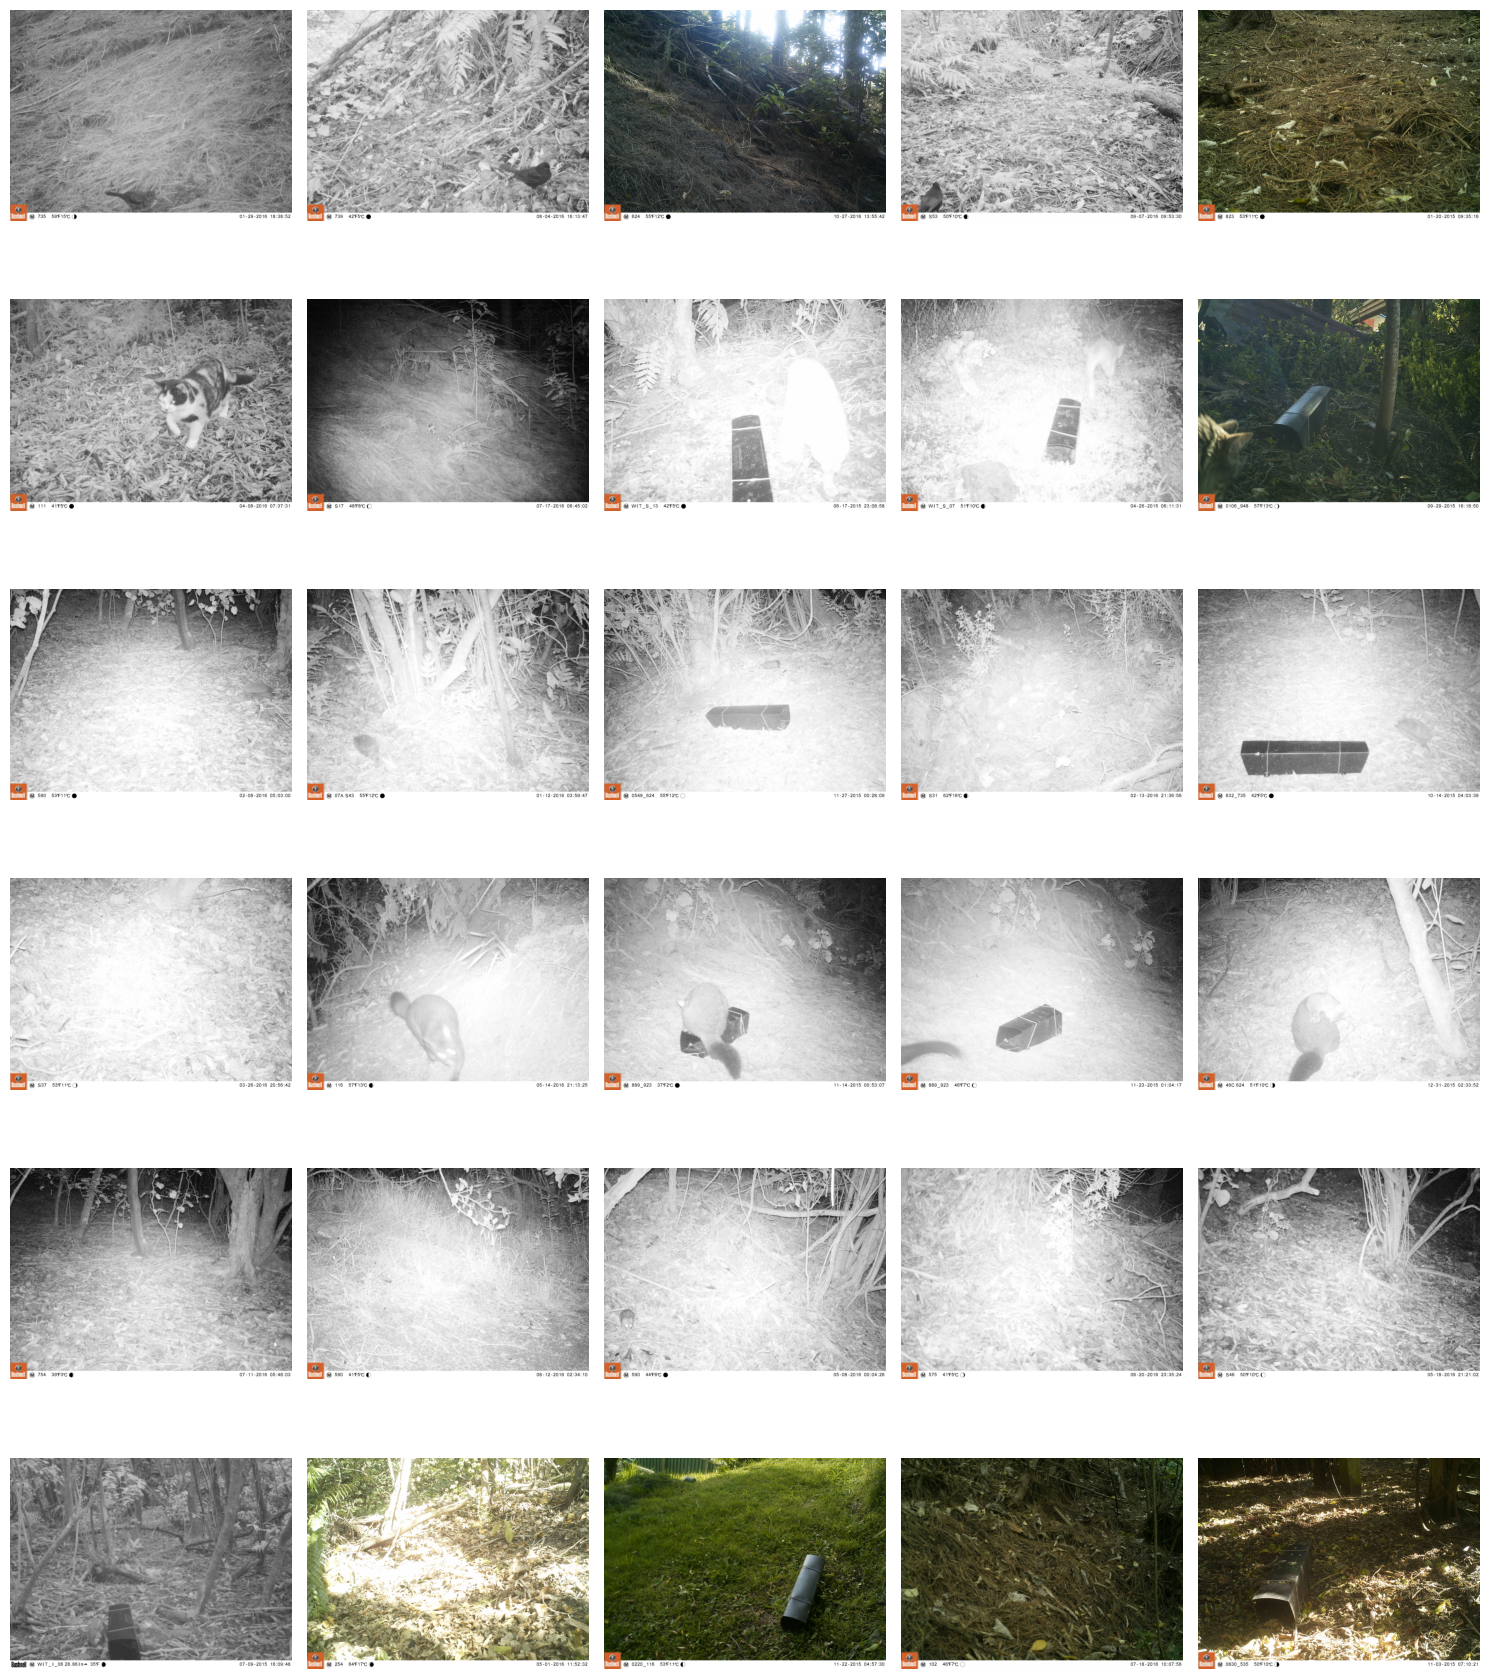

In [66]:
SAMPLES_PER_CLASS = 5

fig, axes = plt.subplots(
    len(PROJECT_CLASSES),
    SAMPLES_PER_CLASS,
    figsize=(15, 18)
)

for row_idx, cls in enumerate(PROJECT_CLASSES):

    class_df = final_clean_df[
        final_clean_df["project_class"] == cls
    ]

    sample_df = class_df.sample(
        n=SAMPLES_PER_CLASS,
        random_state=RANDOM_STATE
    )

    for col_idx, (_, row) in enumerate(sample_df.iterrows()):

        image_path = (
            PROCESSED_DATA_DIR
            / row["split"]
            / row["project_class"]
            / row["file"]
        )

        image = Image.open(image_path)

        axes[row_idx, col_idx].imshow(image)
        axes[row_idx, col_idx].axis("off")

        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(
                cls,
                fontsize=12
            )

plt.tight_layout()
plt.show()